# Kenya Maize, Climate, Prices and Food Security Analysis

**Research question:** How have agricultural production, climate variability, and market dynamics influenced food security across Kenya?

This notebook analyses the annual dataset prepared in SQL. It creates reusable charts and tables for the project portfolio.

In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style='whitegrid', palette='colorblind')
pd.set_option('display.float_format', lambda value: f'{value:,.2f}')

In [2]:
# This finds the project folder whether Jupyter opens in the notebooks folder or the project root.
candidate_roots = [Path.cwd(), Path.cwd().parent.parent, Path(r'C:/Users/Riri/Documents/data science from zero to hero/PROJECTS_ORGANIZED/01_kenya_food_security_project')]
PROJECT_ROOT = next(root for root in candidate_roots if (root / '01_data' / 'processed').exists())
DATA_PATH = PROJECT_ROOT / '01_data' / 'processed' / 'maize_food_security_analysis.csv'
CHART_DIR = PROJECT_ROOT / '06_outputs' / 'charts'
TABLE_DIR = PROJECT_ROOT / '06_outputs' / 'tables'
CHART_DIR.mkdir(parents=True, exist_ok=True)
TABLE_DIR.mkdir(parents=True, exist_ok=True)

df = pd.read_csv(DATA_PATH)
df.columns = df.columns.str.strip().str.lower()
df.head()

,year,maize_production_tonnes,maize_yield_kg_per_ha,maize_area_harvested_ha,avg_maize_retail_price_kes,avg_maize_retail_price_usd,price_records,commodities_used,rainfall_mm,temperature_c,spei,heat_index_35,food_insecurity_percent
0,2000,"2,160,000.00","1,440.00",1500000,NaN,NaN,NaN,NaN,692.00,37.63,-2.20,0.02,NaN
1,2001,"2,790,000.00","1,701.20",1640000,NaN,NaN,NaN,NaN,630.00,37.13,-0.52,0.03,NaN
2,2002,"2,408,596.00","1,512.60",1592315,NaN,NaN,NaN,NaN,630.00,35.88,0.70,0.64,NaN
3,2003,"2,710,848.00","1,622.40",1670914,NaN,NaN,NaN,NaN,630.00,36.63,-0.95,0.33,NaN
4,2004,"2,607,139.00","1,929.30",1351327,NaN,NaN,NaN,NaN,630.00,36.13,-0.49,0.18,NaN


In [3]:
numeric_columns = [
    'year', 'maize_production_tonnes', 'maize_yield_kg_per_ha',
    'maize_area_harvested_ha', 'avg_maize_retail_price_kes',
    'avg_maize_retail_price_usd', 'rainfall_mm', 'temperature_c',
    'spei', 'heat_index_35', 'food_insecurity_percent'
]

for column in numeric_columns:
    df[column] = pd.to_numeric(df[column], errors='coerce')

df = df.sort_values('year').reset_index(drop=True)
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 25 entries, 0 to 24
Data columns (total 13 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   year                        25 non-null     int64  
 1   maize_production_tonnes     25 non-null     float64
 2   maize_yield_kg_per_ha       25 non-null     float64
 3   maize_area_harvested_ha     25 non-null     int64  
 4   avg_maize_retail_price_kes  19 non-null     float64
 5   avg_maize_retail_price_usd  19 non-null     float64
 6   price_records               19 non-null     float64
 7   commodities_used            19 non-null     object 
 8   rainfall_mm                 23 non-null     float64
 9   temperature_c               22 non-null     float64
 10  spei                        24 non-null     float64
 11  heat_index_35               25 non-null     float64
 12  food_insecurity_percent     8 non-null      float64
dtypes: float64(10), int64(2), object(1)
m

In [4]:
# Check coverage before analysing relationships. A blank represents unavailable data, not zero.
coverage = pd.DataFrame({
    'first_year': df[numeric_columns].notna().apply(lambda series: df.loc[series, 'year'].min()),
    'last_year': df[numeric_columns].notna().apply(lambda series: df.loc[series, 'year'].max()),
    'available_years': df[numeric_columns].notna().sum(),
    'missing_years': df[numeric_columns].isna().sum()
})
coverage.to_csv(TABLE_DIR / 'data_coverage_summary.csv')
coverage

,first_year,last_year,available_years,missing_years
year,2000,2024,25,0
maize_production_tonnes,2000,2024,25,0
maize_yield_kg_per_ha,2000,2024,25,0
maize_area_harvested_ha,2000,2024,25,0
avg_maize_retail_price_kes,2006,2024,19,6
avg_maize_retail_price_usd,2006,2024,19,6
rainfall_mm,2000,2022,23,2
temperature_c,2000,2021,22,3
spei,2000,2023,24,1
heat_index_35,2000,2024,25,0


In [5]:
# Year-over-year change shows how production and prices changed from one year to the next.
yoy_columns = ['maize_production_tonnes', 'maize_yield_kg_per_ha', 'avg_maize_retail_price_kes']
yoy = df[['year'] + yoy_columns].copy()
for column in yoy_columns:
    yoy[f'{column}_yoy_percent'] = yoy[column].pct_change() * 100
yoy.to_csv(TABLE_DIR / 'maize_year_over_year_change.csv', index=False)
yoy.tail(10)

,year,maize_production_tonnes,maize_yield_kg_per_ha,avg_maize_retail_price_kes,maize_production_tonnes_yoy_percent,maize_yield_kg_per_ha_yoy_percent,avg_maize_retail_price_kes_yoy_percent
15,2015,"3,825,000.00","1,823.00",49.29,8.88,9.81,-10.23
16,2016,"3,339,000.00","1,428.40",48.95,-12.71,-21.65,-0.70
17,2017,"3,186,000.00","1,527.20",60.54,-4.58,6.92,23.69
18,2018,"4,013,777.44","1,765.60",51.54,25.98,15.61,-14.87
19,2019,"3,582,000.00","1,560.00",55.15,-10.76,-11.64,7.00
20,2020,"3,789,000.00","1,774.10",54.55,5.78,13.72,-1.10
21,2021,"3,304,430.00","1,523.80",48.69,-12.79,-14.11,-10.74
22,2022,"3,082,220.00","1,458.30",49.93,-6.72,-4.30,2.56
23,2023,"4,285,206.00","1,763.40",73.86,39.03,20.92,47.91
24,2024,"4,023,000.00","1,666.20",59.35,-6.12,-5.51,-19.64


In [6]:
# Food-security values are three-year rolling averages, so interpret their trend carefully.
food_security_df = df.dropna(subset=['food_insecurity_percent']).copy()
food_security_summary = pd.DataFrame({
    'metric': ['First food-security value', 'Latest food-security value', 'Change in percentage points'],
    'value': [
        food_security_df['food_insecurity_percent'].iloc[0],
        food_security_df['food_insecurity_percent'].iloc[-1],
        food_security_df['food_insecurity_percent'].iloc[-1] - food_security_df['food_insecurity_percent'].iloc[0]
    ]
})
food_security_summary.to_csv(TABLE_DIR / 'food_security_summary.csv', index=False)
food_security_summary

,metric,value
0,First food-security value,50.70
1,Latest food-security value,72.80
2,Change in percentage points,22.10


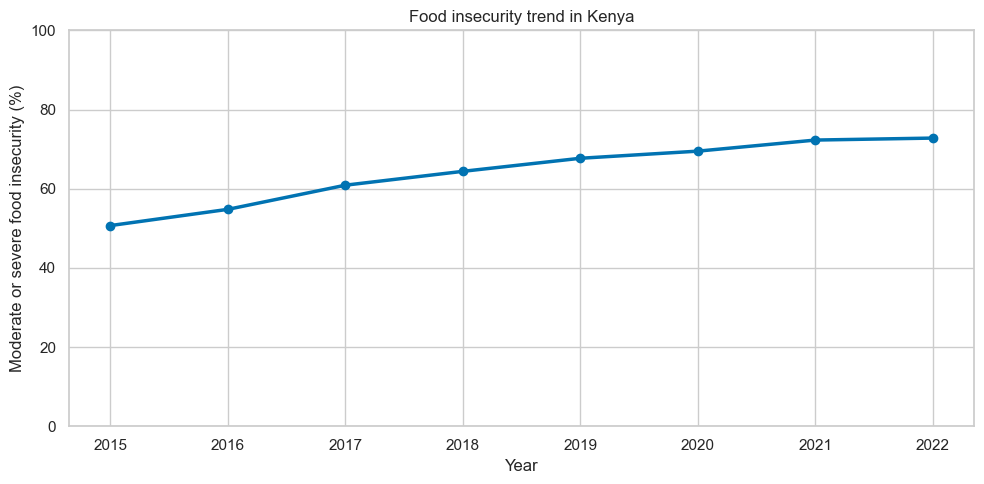

In [7]:
fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(food_security_df['year'], food_security_df['food_insecurity_percent'], marker='o', linewidth=2.5)
ax.set(title='Food insecurity trend in Kenya', xlabel='Year', ylabel='Moderate or severe food insecurity (%)')
ax.set_ylim(0, 100)
fig.tight_layout()
fig.savefig(CHART_DIR / 'food_insecurity_trend.png', dpi=200, bbox_inches='tight')
plt.show()

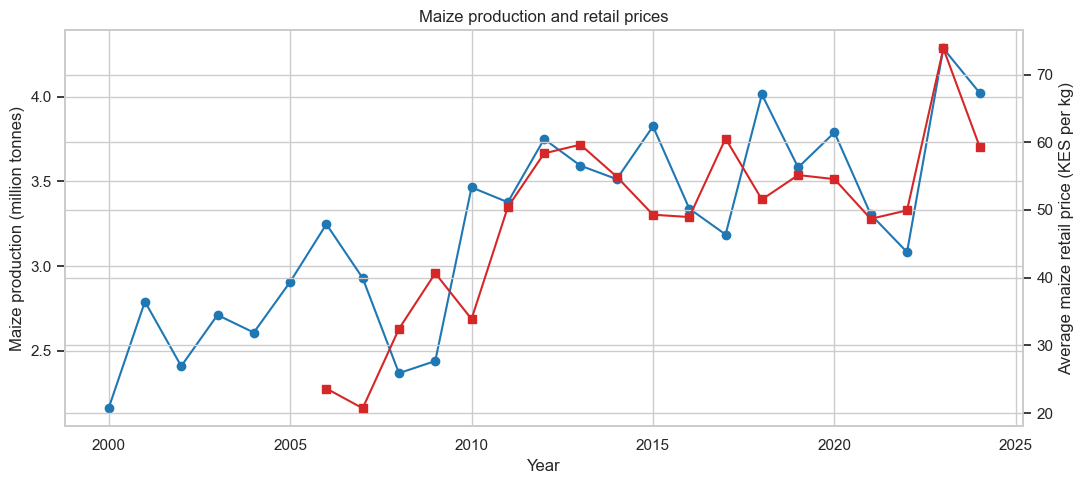

In [8]:
# Production and price use different units, so they are plotted on separate axes.
market_df = df.dropna(subset=['avg_maize_retail_price_kes']).copy()
fig, left_axis = plt.subplots(figsize=(11, 5))
left_axis.plot(df['year'], df['maize_production_tonnes'] / 1_000_000, color='#1f77b4', marker='o')
left_axis.set(xlabel='Year', ylabel='Maize production (million tonnes)')
right_axis = left_axis.twinx()
right_axis.plot(market_df['year'], market_df['avg_maize_retail_price_kes'], color='#d62728', marker='s')
right_axis.set_ylabel('Average maize retail price (KES per kg)')
left_axis.set_title('Maize production and retail prices')
fig.tight_layout()
fig.savefig(CHART_DIR / 'maize_production_and_price.png', dpi=200, bbox_inches='tight')
plt.show()

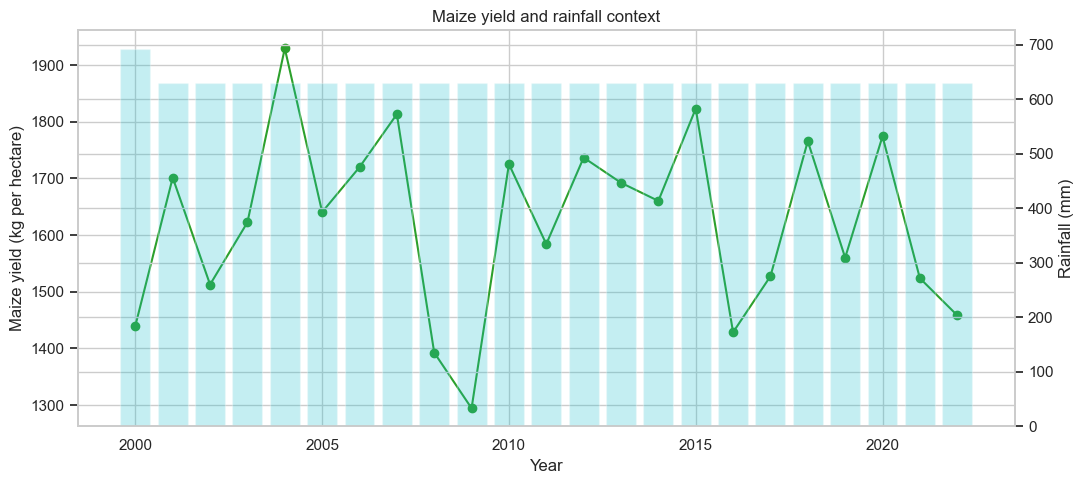

In [9]:
# Yield is a productivity indicator; rainfall adds climate context.
climate_df = df.dropna(subset=['maize_yield_kg_per_ha', 'rainfall_mm']).copy()
fig, left_axis = plt.subplots(figsize=(11, 5))
left_axis.plot(climate_df['year'], climate_df['maize_yield_kg_per_ha'], color='#2ca02c', marker='o')
left_axis.set(xlabel='Year', ylabel='Maize yield (kg per hectare)')
right_axis = left_axis.twinx()
right_axis.bar(climate_df['year'], climate_df['rainfall_mm'], alpha=0.25, color='#17becf')
right_axis.set_ylabel('Rainfall (mm)')
left_axis.set_title('Maize yield and rainfall context')
fig.tight_layout()
fig.savefig(CHART_DIR / 'maize_yield_and_rainfall.png', dpi=200, bbox_inches='tight')
plt.show()

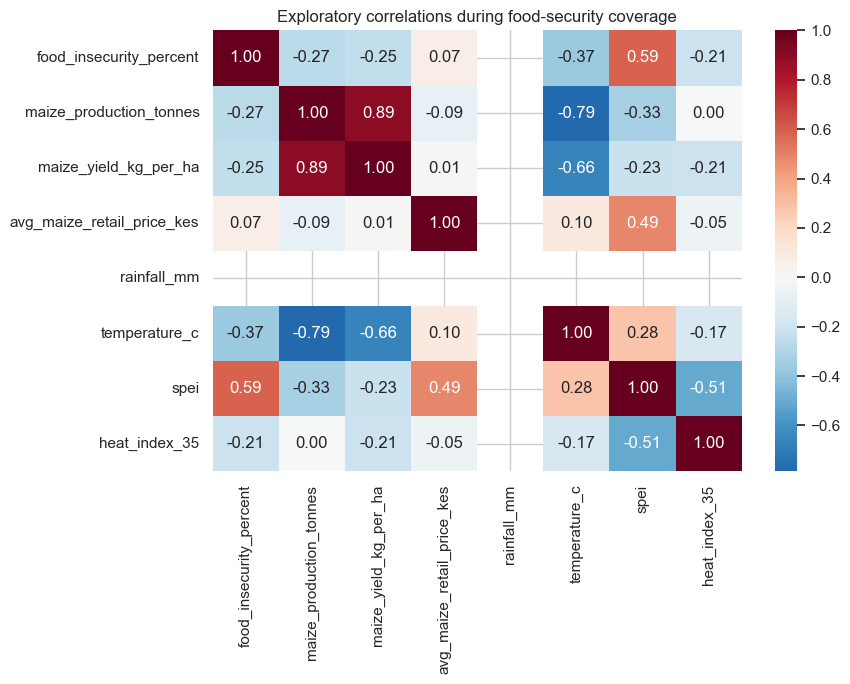

,food_insecurity_percent,maize_production_tonnes,maize_yield_kg_per_ha,avg_maize_retail_price_kes,rainfall_mm,temperature_c,spei,heat_index_35
food_insecurity_percent,1.00,-0.27,-0.25,0.07,NaN,-0.37,0.59,-0.21
maize_production_tonnes,-0.27,1.00,0.89,-0.09,NaN,-0.79,-0.33,0.00
maize_yield_kg_per_ha,-0.25,0.89,1.00,0.01,NaN,-0.66,-0.23,-0.21
avg_maize_retail_price_kes,0.07,-0.09,0.01,1.00,NaN,0.10,0.49,-0.05
rainfall_mm,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
temperature_c,-0.37,-0.79,-0.66,0.10,NaN,1.00,0.28,-0.17
spei,0.59,-0.33,-0.23,0.49,NaN,0.28,1.00,-0.51
heat_index_35,-0.21,0.00,-0.21,-0.05,NaN,-0.17,-0.51,1.00


In [10]:
# Correlations are exploratory. They do not show that one variable caused another.
correlation_columns = [
    'food_insecurity_percent', 'maize_production_tonnes', 'maize_yield_kg_per_ha',
    'avg_maize_retail_price_kes', 'rainfall_mm', 'temperature_c', 'spei', 'heat_index_35'
]
correlation_matrix = food_security_df[correlation_columns].corr(numeric_only=True)
correlation_matrix.to_csv(TABLE_DIR / 'correlation_matrix.csv')

fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(correlation_matrix, annot=True, fmt='.2f', cmap='RdBu_r', center=0, ax=ax)
ax.set_title('Exploratory correlations during food-security coverage')
fig.tight_layout()
fig.savefig(CHART_DIR / 'food_security_correlation_heatmap.png', dpi=200, bbox_inches='tight')
plt.show()
correlation_matrix

## Key findings and limitations

Food insecurity increased from 50.7% to 72.8% in the available rolling-period series, despite continued maize production. This supports an interpretation that food security is about more than availability: prices, household income, climate conditions, market access, and storage can affect whether food is affordable and stable.

The food-security measure has eight observations and is a three-year average. The analysis is therefore exploratory and should not be presented as evidence that any one factor caused food insecurity.